[![Open In Colab](https://img.shields.io/badge/Open_in-Colab-F9AB00?logo=googlecolab&logoColor=white)](https://colab.research.google.com/github/ivanvladimir/maquinas_notebooks/blob/main/basic/Ejemplo_AFD.ipynb)
[![Binder](https://img.shields.io/badge/Launch-Binder-579ACA?logo=jupyter&logoColor=white)](https://mybinder.org/v2/gh/ivanvladimir/maquinas_notebooks/HEAD?labpath=basic%2FEjemplo_AFD.ipynb)
[![Open in Kaggle](https://img.shields.io/badge/Open_in-Kaggle-20BEFF?logo=kaggle&logoColor=white)](https://kaggle.com/kernels/welcome?src=https://github.com/ivanvladimir/maquinas_notebooks/blob/main/basic/Ejemplo_AFD.ipynb)
[![Open in SageMaker Studio Lab](https://img.shields.io/badge/Open_in-SageMaker_Studio_Lab-FF9900)](https://studiolab.sagemaker.aws/import/github/ivanvladimir/maquinas_notebooks/blob/main/basic/Ejemplo_AFD.ipynb)
[![Open in Deepnote](https://img.shields.io/badge/Open_in-Deepnote-3793EF)](https://deepnote.com/launch?url=https://github.com/ivanvladimir/maquinas_notebooks/blob/main/basic/Ejemplo_AFD.ipynb)
[![nbviewer](https://img.shields.io/badge/View_in-nbviewer-F37626?logo=jupyter&logoColor=white)](https://nbviewer.org/github/ivanvladimir/maquinas_notebooks/blob/main/basic/Ejemplo_AFD.ipynb)
[![Open in Codespaces](https://img.shields.io/badge/Open_in-Codespaces-181717?logo=github&logoColor=white)](https://codespaces.new/ivanvladimir/maquinas_notebooks)

This notebook illustrates the machines in the library

Use the navigation view to go the machine of interesst

In [1]:
# Load, or install and load the library
try:
    import maquinas
except ImportError:
    %pip install -q git+https://github.com/ivanvladimir/maquinas
    import maquinas

# Loads machines

In [343]:
from maquinas.io import load_fa, load_pda, load_tm
from maquinas.simulation import Simulation
import ipywidgets as widgets

In [391]:
machines=[]

# Loading machines from strings
machines.append(load_fa("""---
label: "DFA: b in pairs"
description: The number of b symbols is even (DFA)
accepted: [ε, aabb, abab, abbaabbaaaaa]
rejected: [b, ab, bbb, aaaabaababaa]
---
        |  a  |  b  |
 ->q_0] | q_0 | q_1 |
   q_1  | q_1 | q_0 |
"""))

machines.append(load_fa("""---
label: "NDFA: contains ab"
description: The strings contain the ab substring (NDFA)
accepted: [ab, aabb, abab, aaaaaaaaaab, abbaabbaaaaa]
rejected: [ε, a, b, bbb, bbbbbaaaaaaaaaa]
---
        |  a       |  b  |
 ->q_0  | q_0, q_1 | q_0 |
   q_1  | q_0      | q_2 |
   q_2] | q_2      | q_2 |
"""))

machines.append(load_fa("""
---
label: "NDFA-ε: a follow by a b"
description: Aes or not aes ends with a b (NDFA-e)
accepted: [b, ab, aab, aaaaaab]
rejected: [ε, a, ba, abab, aaaaaaba]
---
        |  a       |  b  | epsilon |
 ->q_0  | q_1      |     |  q_1    |
   q_1  | q_1      | q_2 |         |  
   q_2] |          |     |         |
"""
))

machines.append(load_pda("""
---
label: "PDA: aⁿbⁿ"
description: A number of a's followed by the same number of b's (PDA)
accepted: [ε, ab, aabb, aaaaaaaabbbbbbbb]
rejected: [a, b, ba, aaabb, aabbbbb]
---
        |     ε     |          a          |    b    |
 ->q_0  | Z₀/Z₀→q_2 | Z₀/AZ₀→q_0,A/AA→q_0 | A/ε→q_1 |
   q_1  | Z₀/Z₀→q_2 |                     | A/ε→q_1 |
   q_2] |           |                     |         |
"""
))

machines.append(load_pda("""
---
label: "PDA: aⁿbⁿ"
description: A number of a's followed by the same number of b's (PDA)
accepted: [ε, ab, aabb, aaaaaaaabbbbbbbb]
rejected: [a, b, ba, aaabb, aabbbbb]
---
        |     ε     |          a          |    b    |
 ->q_0  | Z₀/Z₀→q_2 | Z₀/AZ₀→q_0,A/AA→q_0 | A/ε→q_1 |
   q_1  | Z₀/Z₀→q_2 |                     | A/ε→q_1 |
   q_2] |           |                     |         |
"""
))

machines.append(load_pda("""
---
label: "TSPDA: aⁿbⁿcⁿ"
description: A number of a's followed by the same number of b's, follow by the same number of c's (TSPDA)
accepted: [ε, abc, aabbcc, aaaaaaaabbbbbbbbcccccccc]
rejected: [a, b,c, ab, ba, ac, ca, cb, aaabbbcc, aabbccccc]
---
        |        ε        |                a                 |      b      |       c       |
 ->q_0  |                 | Z₀/AZ₀,Z₀/AZ₀→q_0, A/AA,A/AA→q_0 | A/ε,A/A→q_1 |               |
   q_1  |                 |                                  | A/ε,A/A→q_1 | Z₀/Z₀,A/ε→q_2 |
   q_2  | Z₀/Z₀,Z₀/Z₀→q_3 |                                  |             | Z₀/Z₀,A/ε→q_2 |
   q_3] |                 |                                  |             |               |
"""))

machines.append(load_tm("""
---
label: "LBA: aⁿbⁿ, n>0"
description: A number of a's followed by the same number of b's (LBA)
accepted: [ab, aabb, aaaaaaaabbbbbbbb]
rejected: [ε, a, b, ba, aaabb, aabbbbb]
---
        |     𝖁     |     X     |     Y     |     a     |     b     |
 ->q_0  |           |           | Y/Y→q_3:R | a/X→q_1:R |           |
   q_1  |           |           | Y/Y→q_1:R | a/a→q_1:R | b/Y→q_2:L |
   q_2  |           | X/X→q_0:R | Y/Y→q_2:L | a/a→q_2:L |           |
   q_3  | 𝖁/𝖁→q_4:R |           | Y/Y→q_3:R |           |           |
   q_4] |           |           |           |           |           |
""",lba=True))

machines.append(load_tm("""
---
label: "TM: aⁿbⁿ, n>0"
description: A number of a's followed by the same number of b's (MT)
accepted: [ab, aabb, aaaaaaaabbbbbbbb]
rejected: [ε, a, b, ba, aaabb, aabbbbb]
---
        |     𝖁     |     X     |     Y     |     a     |     b     |
 ->q_0  |           |           | Y/Y→q_3:R | a/X→q_1:R |           |
   q_1  |           |           | Y/Y→q_1:R | a/a→q_1:R | b/Y→q_2:L |
   q_2  |           | X/X→q_0:R | Y/Y→q_2:L | a/a→q_2:L |           |
   q_3  | 𝖁/𝖁→q_4:R |           | Y/Y→q_3:R |           |           |
   q_4] |           |           |           |           |           |
"""))

## Select the machine to explore

In [398]:
dropdown = widgets.Dropdown(
    options=[(m.metadata.extra()['label'],m) for m in machines],
    description="Autómata:",
)
dropdown

Dropdown(description='Autómata:', options=(('DFA: b in pairs', <maquinas.regular.dfa.DeterministicFiniteAutoma…

In [406]:
machine=dropdown.value

# Testing shared api with machines

## Prints elements of machine

Shows the elements of the machine

Shows the information from the machine, short and long version

In [407]:
machine.print_info()

Description : A number of a's followed by the same number of b's (LBA)

In [408]:
machine.print_long_info()

Description : A number of a's followed by the same number of b's (LBA)
Accepted    : ab, aabb, aaaaaaaabbbbbbbb
Rejected    : ε, a, b, ba, aaabb, aabbbbb
Label       : LBA: aⁿbⁿ, n>0

In [409]:
machine.print_summary()

States  : q_0, q_1, q_2, q_3, q_4
Sigma   : X, Y, a, b
Gamma   : 𝖁, <, >, X, Y, a, b
Initial : q_0
Aceptors: {q_4}
Transitions:
 q_0,Y/Y → q_3:R
 q_0,a/X → q_1:R
 q_1,Y/Y → q_1:R
 q_1,a/a → q_1:R
 q_1,b/Y → q_2:L
 q_2,X/X → q_0:R
 q_2,Y/Y → q_2:L
 q_2,a/a → q_2:L
 q_3,𝖁/𝖁 → q_4:R
 q_3,Y/Y → q_3:R

## Renders mathematical representation

In [410]:
machine

In [411]:
print(machine.latex())

\begin{array}{l}M = (Q, \Sigma, \Gamma, \delta, q_0, \text{<}, \text{>}, A) \\ Q = \{q_{0}, q_{1}, q_{2}, q_{3}, q_{4}\} \\ \Sigma = \{X, Y, a, b\} \\ \Gamma = \{\sqcup, \text{<}, \text{>}, X, Y, a, b\} \\ q_0 = q_{0} \\ A = \{q_{4}\} \\ \delta : Q \times \Gamma \to Q \times \Gamma \times \{L, R, N\}\end{array}\qquad \begin{array}{r|ccccccc}\delta & \sqcup & \text{<} & \text{>} & X & Y & a & b \\ \hline \to q_{0} & - & - & - & - & (q_{3}, Y, R) & (q_{1}, X, R) & - \\ q_{1} & - & - & - & - & (q_{1}, Y, R) & (q_{1}, a, R) & (q_{2}, Y, L) \\ q_{2} & - & - & - & (q_{0}, X, R) & (q_{2}, Y, L) & (q_{2}, a, L) & - \\ q_{3} & (q_{4}, \sqcup, R) & - & - & - & (q_{3}, Y, R) & - & - \\ {*}q_{4} & - & - & - & - & - & - & - \\\end{array}


Copy string and paste it in latex code, to text it here: https://latexeditor.lagrida.com/

## Shows transition function as table

In [412]:
machine.table()

,𝖁,<,>,X,Y,a,b
⟶q_0,∅,∅,∅,∅,"Y,R→q_3","X,R→q_1",∅
q_1,∅,∅,∅,∅,"Y,R→q_1","a,R→q_1","Y,L→q_2"
q_2,∅,∅,∅,"X,R→q_0","Y,L→q_2","a,L→q_2",∅
q_3,"𝖁,R→q_4",∅,∅,∅,"Y,R→q_3",∅,∅
q_4,∅,∅,∅,∅,∅,∅,∅


## Shows diagram of machine

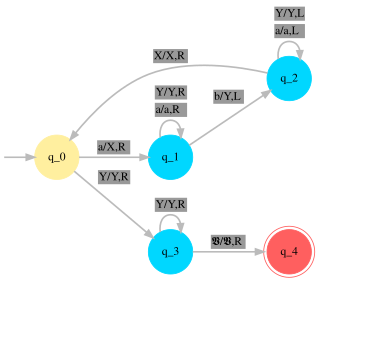

In [413]:
machine.draw()

## Testing string

In [414]:
testing_string=machine.metadata.accepted[-1]
print("String to test:",testing_string)

String to test: aaaaaaaabbbbbbbb


In [415]:
machine.accepts(testing_string)

True

In [416]:
machine.print_transitions(testing_string)

< 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 q_0 a a a a a a a a b b b b b b b b 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 >
⊢ < 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 X q_1 a a a a a a a b b b b b b b b 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 >
⊢ < 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 X a q_1 a a a a a a b b b b b b b b 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 >
⊢ < 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 X a a q_1 a a a a a b b b b b b b b 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 >
⊢ < 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 X a a a q_1 a a a a b b b b b b b b 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 >
⊢ < 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 X a a a a q_1 a a a b b b b b b b b 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 >
⊢ < 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 X a a a a a q_1 a a b b b b b b b b 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 >
⊢ < 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 X a a a a a a q_1 a b b b b b b b b 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 >
⊢ < 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 X a a a a a a a q_1 b b b b b b b b 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 𝖁 >
⊢ < 𝖁 𝖁 𝖁 𝖁 

In [417]:
# recover last state
res=machine.delta_extended(None,testing_string)
res

{TapeConfiguration(state='q_4', tape=('<', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', 'X', 'X', 'X', 'X', 'X', 'X', 'X', 'X', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '>'), head=35, offset=0)}

In [418]:
print(f"With state {res} can we accept?", "yes" if machine.acceptor(res) else "no" )

With state {TapeConfiguration(state='q_4', tape=('<', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', 'X', 'X', 'X', 'X', 'X', 'X', 'X', 'X', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '𝖁', '>'), head=35, offset=0)} can we accept? yes


In [419]:
print("Analysing string that should be accepted")
for t in machine.metadata.accepted:
    print(f"  Does {t if len(t) > 0 else 'ε' } is accepted?", "✓" if machine.accepts(t) else "𐄂" )

Analysing string that should be accepted
  Does ab is accepted? ✓
  Does aabb is accepted? ✓
  Does aaaaaaaabbbbbbbb is accepted? ✓


In [420]:
print("Analysing string that should be rejected")
for t in machine.metadata.rejected:
    print(f"  Does {t if len(t) > 0 else 'ε' } is accepted?", "✓" if machine.accepts(t) else "𐄂" )

Analysing string that should be rejected
  Does ε is accepted? 𐄂
  Does a is accepted? 𐄂
  Does b is accepted? 𐄂
  Does ba is accepted? 𐄂
  Does aaabb is accepted? 𐄂
  Does aabbbbb is accepted? 𐄂


## Creating animation and showing it

In [421]:
# Creates an animation and shows it
machine.save_animation(testing_string, "machine_animation.svg",show=True)

In [422]:
machine.save_animation(machine.metadata.rejected[-1], "machine_animation.svg",show=True)

## Simulation

In [423]:
s=Simulation(machine,testing_string)
s.run()